# Demo 5｜非随机触达的匹配与敏感性分析

目标是估计运营触达对留存的影响。处理并非随机，需先陈述“给定触达前协变量后无未测混杂”和重叠性假设。模拟数据刻意设置高活跃用户更易触达。

**数据声明**：以下均为固定随机种子生成的模拟数据，不代表真实滴滴业务效果。图中的英文标签用于避免本地中文字体依赖。

## 模拟与选择偏差

`pre_activity`、`city`、`channel` 均在触达前；`treated` 运营触达；`retained` 七日留存。还模拟一个不可观测的兴趣变量，仅用于展示敏感性，不纳入主估计。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style='whitegrid')
rng = np.random.default_rng(20261028)
from scipy.special import expit
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
n=7000;activity=rng.normal(size=n);city=rng.integers(0,4,n);channel=rng.binomial(1,.4,n);hidden=rng.normal(size=n)
ps_true=expit(-.3+.9*activity+.3*(city==0)+.25*channel+.25*hidden)
treated=rng.binomial(1,ps_true)
p_y=expit(-.4+.8*activity+.25*(city==0)+.2*channel+.3*hidden+.2*treated)
retained=rng.binomial(1,p_y)
df=pd.DataFrame({'pre_activity':activity,'city':city,'channel':channel,'hidden_for_simulation':hidden,'treated':treated,'retained':retained})
print(df.head());print('Raw retention gap:',df.groupby('treated').retained.mean().diff().iloc[-1])

   pre_activity  city  channel  hidden_for_simulation  treated  retained
0     -0.203041     3        0               0.667523        0         0
1     -0.627083     1        1              -1.478668        0         0
2     -0.246317     1        0               0.576494        1         1
3      0.194973     1        1               0.871721        1         1
4     -1.020880     0        1               0.812402        0         0
Raw retention gap: 0.18590498651583992


## 倾向得分、重叠与协变量平衡

仅使用触达前可观测变量拟合倾向得分。先看两组得分分布；极端得分会使逆概率权重不稳定。以下估计的是重叠样本内的平均效果。

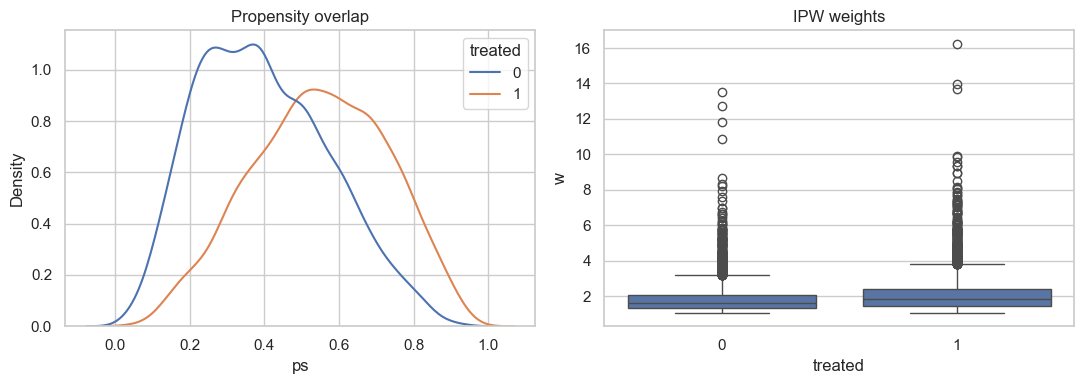

        feature    before     after
0  pre_activity  0.800051 -0.009248
1       channel  0.097267  0.005099
2        city_1 -0.042105  0.001748
3        city_2 -0.076320 -0.008680
4        city_3 -0.044767 -0.000815


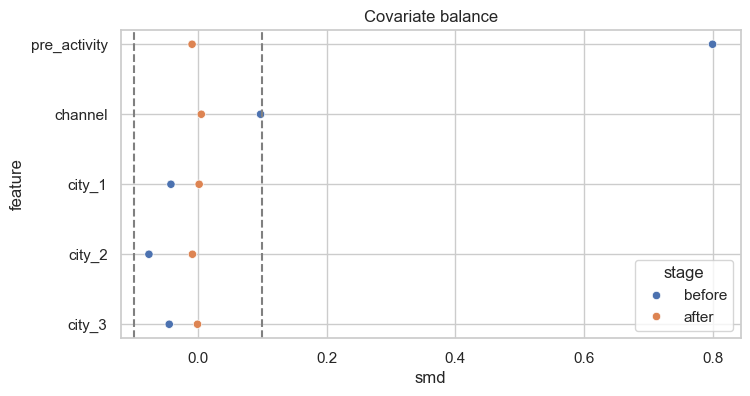

In [2]:
X=pd.get_dummies(df[['pre_activity','city','channel']],columns=['city'],drop_first=True)
model=LogisticRegression(max_iter=1000).fit(X,df.treated);df['ps']=np.clip(model.predict_proba(X)[:,1],.02,.98)
keep=df.ps.between(.05,.95);d=df[keep].copy();d['w']=np.where(d.treated==1,1/d.ps,1/(1-d.ps))
fig,ax=plt.subplots(1,2,figsize=(11,4));sns.kdeplot(data=df,x='ps',hue='treated',ax=ax[0]);ax[0].set_title('Propensity overlap');sns.boxplot(data=d,x='treated',y='w',ax=ax[1]);ax[1].set_title('IPW weights');plt.tight_layout();plt.show()
def smd(v,t,w=None):
 w=np.ones(len(v)) if w is None else np.asarray(w);a=np.asarray(v);t=np.asarray(t);mu1=np.average(a[t==1],weights=w[t==1]);mu0=np.average(a[t==0],weights=w[t==0]);return (mu1-mu0)/np.sqrt((np.var(a[t==1])+np.var(a[t==0]))/2)
balance=pd.DataFrame({'feature':X.columns,'before':[smd(X.loc[keep,c],d.treated) for c in X],'after':[smd(X.loc[keep,c],d.treated,d.w) for c in X]});print(balance)
b=balance.melt('feature',var_name='stage',value_name='smd');plt.figure(figsize=(8,4));sns.scatterplot(data=b,x='smd',y='feature',hue='stage');plt.axvline(-.1,color='gray',ls='--');plt.axvline(.1,color='gray',ls='--');plt.title('Covariate balance');plt.show()

## 原始差异、加权与匹配

IPW 估计 ATE；1:1 最近邻匹配用处理组匹配对照组，目标更接近 ATT。这里的朴素区间仅用于教学，真实匹配推断应考虑匹配的不确定性。

        method    effect
0          Raw  0.185905
1      IPW ATE  0.056191
2  Matched ATT  0.060569


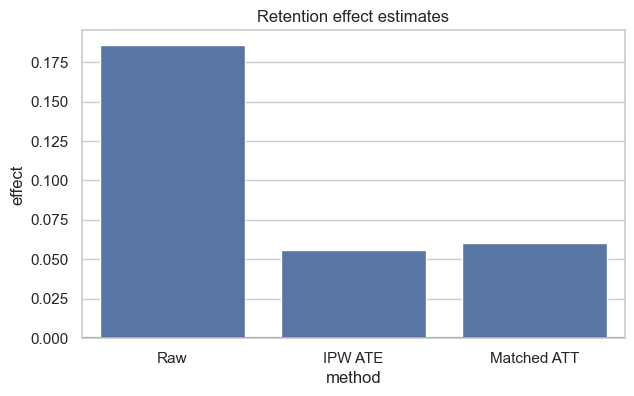

In [3]:
raw=df.groupby('treated').retained.mean().diff().iloc[-1]
ipw=np.average(d.loc[d.treated==1,'retained'],weights=d.loc[d.treated==1,'w'])-np.average(d.loc[d.treated==0,'retained'],weights=d.loc[d.treated==0,'w'])
t=d[d.treated==1];c=d[d.treated==0];nn=NearestNeighbors(n_neighbors=1).fit(c[['ps']]);dist,idx=nn.kneighbors(t[['ps']]);pairs=t[dist[:,0]<.03].copy();matched=c.iloc[idx[dist[:,0]<.03,0]]
att=pairs.retained.mean()-matched.retained.mean()
est=pd.DataFrame({'method':['Raw','IPW ATE','Matched ATT'],'effect':[raw,ipw,att]});print(est)
plt.figure(figsize=(7,4));sns.barplot(data=est,x='method',y='effect');plt.axhline(0,color='black');plt.title('Retention effect estimates');plt.show()

## 未测混杂敏感性与决策

用透明的偏差参数做情景分析：若未观测因素造成 1、3、5 个百分点的虚假提升，调整后的效果会如何变化？这不是正式的识别保证，而是帮助业务方理解结论脆弱性。模拟中的隐藏变量仅用于事后校验。

   assumed_unmeasured_bias  adjusted_ipw_effect
0                     0.00             0.056191
1                     0.01             0.046191
2                     0.03             0.026191
3                     0.05             0.006191
4                     0.08            -0.023809


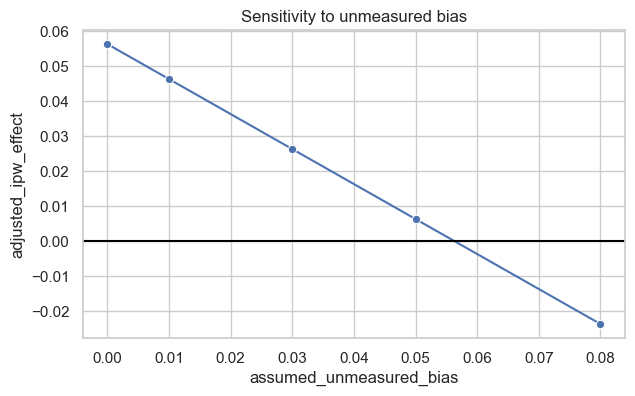

Simulation-only hidden variable difference: 0.19642452633578233
Decision: if modest unmeasured bias changes the sign, prioritize a randomized follow-up rather than claim causality.


In [4]:
bias=np.array([0,.01,.03,.05,.08]);sensitivity=pd.DataFrame({'assumed_unmeasured_bias':bias,'adjusted_ipw_effect':ipw-bias});print(sensitivity)
plt.figure(figsize=(7,4));sns.lineplot(data=sensitivity,x='assumed_unmeasured_bias',y='adjusted_ipw_effect',marker='o');plt.axhline(0,color='black');plt.title('Sensitivity to unmeasured bias');plt.show()
print('Simulation-only hidden variable difference:',df.groupby('treated').hidden_for_simulation.mean().diff().iloc[-1])
print('Decision: if modest unmeasured bias changes the sign, prioritize a randomized follow-up rather than claim causality.')

## 模拟结果解读与决策摘要

- 原始留存差约 **+18.6 个百分点**。处理组的实验前活跃度明显更高，原始 SMD≈0.80，简单组间比较严重混入选择偏差。
- 加权后各可观测协变量的 SMD 接近零；IPW 估计约 **+5.6 个百分点**，倾向得分匹配的 ATT 约 **+6.1 个百分点**。两个估计目标不同，不应要求数值完全一致。
- 若未观测因素带来约 5 个百分点的上偏，加权结果已接近零；8 个百分点上偏会使结论反向。模拟中确实存在未纳入主估计的兴趣变量。
- 因而这份观察性结果适合形成随机验证的优先级，不能直接认定触达带来了上述留存增量。真实研究还需检查权重极端值、共同支持和标准误。


## 实证分析接入

当前目录没有可用于此案例的真实数据，故不把模拟结论解释为实际业务结论。接入真实数据时：①取得脱敏且获授权的数据；②核对数据字典、随机化/触达机制和时间窗；③用真实数据替换模拟数据生成单元；④重跑质量诊断与敏感性分析；⑤在审阅关键识别假设后更新决策摘要。